In [1]:
import re
import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')

text = (
    "I LIKE SLEEPING .\n "
    "IT IS KNOWN AS THE BEST EXCERCISE FOR YOUR MIDS AND BODY .\n "
    "SLEEPING  10 HRS A DAY KEEPS DOCTOTR AWAY. \n "
    "THE BEST COMIBNATION TO GET A PERFECT SLEEP IS TO PUT YOUR "
    "AC ON 18 C IN TERBO MODE , GRAB A BLANKET AND PLAY DIM MUSIC .  \n"
)

text_lower = text.lower()
text_clean = re.sub(r'[^\w\s]', '', text_lower)

words_split = text_clean.split()
words_nltk = word_tokenize(text_clean)

print("Python split() result:", words_split)
print("NLTK word_tokenize() result:", words_nltk)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Python split() result: ['i', 'like', 'sleeping', 'it', 'is', 'known', 'as', 'the', 'best', 'excercise', 'for', 'your', 'mids', 'and', 'body', 'sleeping', '10', 'hrs', 'a', 'day', 'keeps', 'doctotr', 'away', 'the', 'best', 'comibnation', 'to', 'get', 'a', 'perfect', 'sleep', 'is', 'to', 'put', 'your', 'ac', 'on', '18', 'c', 'in', 'terbo', 'mode', 'grab', 'a', 'blanket', 'and', 'play', 'dim', 'music']
NLTK word_tokenize() result: ['i', 'like', 'sleeping', 'it', 'is', 'known', 'as', 'the', 'best', 'excercise', 'for', 'your', 'mids', 'and', 'body', 'sleeping', '10', 'hrs', 'a', 'day', 'keeps', 'doctotr', 'away', 'the', 'best', 'comibnation', 'to', 'get', 'a', 'perfect', 'sleep', 'is', 'to', 'put', 'your', 'ac', 'on', '18', 'c', 'in', 'terbo', 'mode', 'grab', 'a', 'blanket', 'and', 'play', 'dim', 'music']


In [2]:

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
text = (
    "I LIKE SLEEPING .\n "
    "IT IS KNOWN AS THE BEST EXCERCISE FOR YOUR MINDS AND BODY .\n "
    "SLEEPING  10 HRS A DAY KEEPS DOCTOTR AWAY. \n "
    "THE BEST COMIBNATION TO GET A PERFECT SLEEP IS TO PUT YOUR "
    "AC ON 18 C IN TERBO MODE , GRAB A BLANKET AND PLAY DIM MUSIC .  \n"
)

words_alpha = re.findall(r'[A-Za-z]+', text.lower())

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words_alpha if w not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]

print("Filtered Words:", filtered_words)
print("-" * 50)
print("Stemmed Output:  ", stemmed_words)
print("-" * 50)
print("Lemmatized Output:", lemmatized_words)



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Filtered Words: ['like', 'sleeping', 'known', 'best', 'excercise', 'minds', 'body', 'sleeping', 'hrs', 'day', 'keeps', 'doctotr', 'away', 'best', 'comibnation', 'get', 'perfect', 'sleep', 'put', 'ac', 'c', 'terbo', 'mode', 'grab', 'blanket', 'play', 'dim', 'music']
--------------------------------------------------
Stemmed Output:   ['like', 'sleep', 'known', 'best', 'excercis', 'mind', 'bodi', 'sleep', 'hr', 'day', 'keep', 'doctotr', 'away', 'best', 'comibn', 'get', 'perfect', 'sleep', 'put', 'ac', 'c', 'terbo', 'mode', 'grab', 'blanket', 'play', 'dim', 'music']
--------------------------------------------------
Lemmatized Output: ['like', 'sleeping', 'known', 'best', 'excercise', 'mind', 'body', 'sleeping', 'hr', 'day', 'keep', 'doctotr', 'away', 'best', 'comibnation', 'get', 'perfect', 'sleep', 'put', 'ac', 'c', 'terbo', 'mode', 'grab', 'blanket', 'play', 'dim', 'music']


In [3]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "Apple just announced a powerful new smartphone with an upgraded battery life.",
    "The crispy chicken burger at the new downtown diner was absolutely delicious.",
    "SLEEP IS THE BEST EXERCISE FOR YOUR MIND AND BODY"
]

cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("BAG OF WORDS")
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()))

tf = TfidfVectorizer()
tfidf = tf.fit_transform(texts)

print("\nTF IDF")
print(pd.DataFrame(tfidf.toarray(), columns=tf.get_feature_names_out()))

for i in range(len(texts)):
    scores = tfidf[i].toarray()[0]
    top = scores.argsort()[-3:][::-1]

    print("\nTEXT", i + 1)
    for j in top:
        print(tf.get_feature_names_out()[j], round(scores[j], 3))


BAG OF WORDS
   absolutely  an  and  announced  apple  at  battery  best  body  burger  \
0           0   1    0          1      1   0        1     0     0       0   
1           1   0    0          0      0   1        0     0     0       1   
2           0   0    1          0      0   0        0     1     1       0   

   ...  mind  new  powerful  sleep  smartphone  the  upgraded  was  with  your  
0  ...     0    1         1      0           1    0         1    0     1     0  
1  ...     0    1         0      0           0    2         0    1     0     0  
2  ...     1    0         0      1           0    1         0    0     0     1  

[3 rows x 30 columns]

TF IDF
   absolutely        an       and  announced     apple        at   battery  \
0    0.000000  0.307461  0.000000   0.307461  0.307461  0.000000  0.307461   
1    0.289983  0.000000  0.000000   0.000000  0.000000  0.289983  0.000000   
2    0.000000  0.000000  0.323112   0.000000  0.000000  0.000000  0.000000   

       bes

In [4]:

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence is used in many applications.
AI can learn from data.
It helps in solving difficult problems.
AI is used in phones and computers.
Many people use AI tools for daily work.
"""

text2 = """
Cloud computing is used for storing data.
Cloud services work through the internet.
It helps people access files from anywhere.
Cloud technology is used in many applications.
Many companies use cloud tools for daily work.
"""

def clean_text(t):
    t = t.lower()
    t = re.sub(r'[^a-z\s]', '', t)
    return t.split()

words1 = clean_text(text1)
words2 = clean_text(text2)

set1 = set(words1)
set2 = set(words2)

common = set1.intersection(set2)
total = set1.union(set2)

jaccard = len(common) / len(total)

print("COMMON WORDS")
print(common)

print("\nJACCARD SIMILARITY")
print(jaccard)

tf = TfidfVectorizer()
matrix = tf.fit_transform([" ".join(words1), " ".join(words2)])

cosine = cosine_similarity(matrix[0:1], matrix[1:2])

print("\nCOSINE SIMILARITY")
print(cosine[0][0])


COMMON WORDS
{'applications', 'helps', 'for', 'in', 'use', 'people', 'tools', 'used', 'is', 'many', 'from', 'it', 'work', 'daily', 'data'}

JACCARD SIMILARITY
0.39473684210526316

COSINE SIMILARITY
0.3678381666096358



REVIEW: The phone is amazing and battery life is great
POLARITY: 0.7000000000000001
SUBJECTIVITY: 0.825
SENTIMENT: Positive

REVIEW: I love this laptop it works really fast
POLARITY: 0.35
SUBJECTIVITY: 0.6
SENTIMENT: Positive

REVIEW: The food was terrible and service was bad
POLARITY: -0.8499999999999999
SUBJECTIVITY: 0.8333333333333333
SENTIMENT: Negative

REVIEW: This product is okay nothing special
POLARITY: 0.4285714285714286
SUBJECTIVITY: 0.5357142857142857
SENTIMENT: Positive

REVIEW: The headphones are excellent and sound is beautiful
POLARITY: 0.75
SUBJECTIVITY: 0.7999999999999999
SENTIMENT: Positive

REVIEW: The delivery was slow and disappointing
POLARITY: -0.45
SUBJECTIVITY: 0.5499999999999999
SENTIMENT: Negative


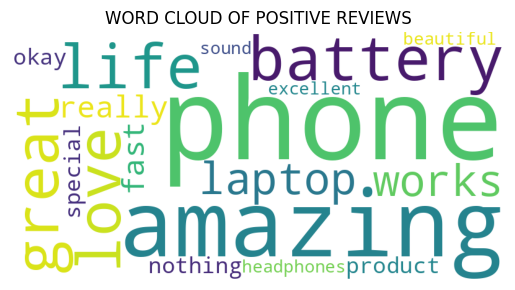

In [5]:

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "The phone is amazing and battery life is great",
    "I love this laptop it works really fast",
    "The food was terrible and service was bad",
    "This product is okay nothing special",
    "The headphones are excellent and sound is beautiful",
    "The delivery was slow and disappointing"
]

positive_reviews = []

for review in reviews:
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nREVIEW:", review)
    print("POLARITY:", polarity)
    print("SUBJECTIVITY:", subjectivity)
    print("SENTIMENT:", sentiment)

positive_text = " ".join(positive_reviews)

if positive_text:
    wc = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.imshow(wc)
    plt.axis("off")
    plt.title("WORD CLOUD OF POSITIVE REVIEWS")
    plt.show()


In [6]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tf.random.set_seed(42)

text = """
I like sleeping because it makes me feel fresh and relaxed.
After a long day of college I just want to go back to my room and sleep.
A good sleep helps my mind and body recover from all the work.
I usually turn on the air conditioner and grab my blanket.
Sometimes I play some slow music before going to bed.
Sleeping is my favorite thing to do when I have free time.
I think everyone should get enough sleep every day.
Good sleep helps us stay active and focus on our work.
It also makes the next morning better.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

tokens = tokenizer.texts_to_sequences([text])[0]

sequences = []

for i in range(1, len(tokens)):
    sequences.append(tokens[:i + 1])

max_len = max(len(s) for s in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_len,
    padding='pre'
)

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential()

model.add(Embedding(total_words, 32))
model.add(LSTM(64))
model.add(Dense(total_words, activation='softmax'))

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=100, verbose=0)

print("MODEL TRAINING COMPLETED")

seed_text = "good sleep"

for i in range(3):
    result = seed_text

    for j in range(8):
        seq = tokenizer.texts_to_sequences([result])[0]
        seq = pad_sequences(
            [seq],
            maxlen=max_len - 1,
            padding='pre'
        )

        prediction = model.predict(seq, verbose=0)
        next_word_id = np.argmax(prediction[0])

        next_word = tokenizer.index_word.get(next_word_id)

        if next_word is None or next_word_id == 0:
            break

        result = result + " " + next_word

    print("GENERATED LINE", i + 1, ":", result)

    seed_text = result.split()[-2] + " " + result.split()[-1]


MODEL TRAINING COMPLETED
GENERATED LINE 1 : good sleep like because it makes me feel fresh fresh
GENERATED LINE 2 : fresh fresh because it makes me me fresh fresh relaxed
GENERATED LINE 3 : fresh relaxed because because it makes me feel fresh fresh
